In [2]:
import numpy as np

In [28]:
def get_geneset_category_averages(extracted_geneset_matrix, category_dict, raw_categories):
    result = {}
    
    for category, keywords in category_dict.items():
        column_indices = [i for i, c in enumerate(raw_categories) if c in keywords]
        average_columns = np.mean(extracted_geneset_matrix[:, column_indices], axis=1)
        result[category] = average_columns.tolist()
    
    return result

def convert_to_matrix(result_dict):
    matrix = []
    for category, values in result_dict.items():
        matrix.append(values)
    
    return np.array(matrix).T

# OOE but with an additional log2 that I later realized is not needed (we already did log2 during QN processing)
# def perform_ooe(matrix):
#     row_avgs = np.mean(matrix, axis=1)  # Calculate row averages
#     normalized_matrix = matrix / row_avgs[:, np.newaxis]  # Divide each element by the row average
#     log2_matrix = np.log2(normalized_matrix)  # Take the logarithm base 2 of each element
    
#     return log2_matrix

def perform_ooe(extracted_matrix, geneset_catAvg_matrix):
    
    # Create an empty matrix to store the results
    result_matrix = np.empty_like(extracted_matrix, dtype=float)
    
    # Iterate over each row in extracted_matrix
    for i, row in enumerate(extracted_matrix):
        # Calculate the average of the corresponding index row in geneset_catAvg_matrix
        avg_row = geneset_catAvg_matrix[i]
        avg_row = np.array(avg_row)
        avg = np.mean(avg_row)
        
        # Perform element-wise division and store the results in the result_matrix
        result_matrix[i] = row / avg
        
    return result_matrix

def perform_ooe_system(geneset_catAvg_matrix):
    geneset_catAvg_matrix = np.array(geneset_catAvg_matrix)

    row_avgs = np.mean(geneset_catAvg_matrix, axis=1)  # Calculate row averages

    geneset_systemAvg_ooe_matrix = geneset_catAvg_matrix / row_avgs[:, np.newaxis]

    return geneset_systemAvg_ooe_matrix

def get_enrichment_value(matrix):
    averages = np.mean(matrix, axis=0)  # Calculate row averages
    return averages

extracted_geneset_matrix = np.array([[1,2,3,4,5],[6,7,8,9,10],[11,12,13,14,15]])
category_dict = {"Cardiovascular System": ["heart", "atrium"], "Connective Tissue": ["adipose"]}
raw_categories = ["heart", "atrium", "heart", "adipose", "adipose"]

geneset_catAvg_dict = get_geneset_category_averages(extracted_geneset_matrix, category_dict, raw_categories)
print("Geneset Category Averaged - Dict Form:")
print(geneset_catAvg_dict)
print()

geneset_catAvg_matrix = convert_to_matrix(geneset_catAvg_dict)
print("Dict to Matrix")
print(geneset_catAvg_matrix)
print()

ooe_system_matrix = perform_ooe_system(geneset_catAvg_matrix)
print("OOE System Matrix")
print("-----------------")
print(ooe_system_matrix)
print()

ooe_matrix = perform_ooe(extracted_geneset_matrix, geneset_catAvg_matrix)
print("OOE Matrix")
print(ooe_matrix)
print()

geneset_catAvg_ooe_dict = get_geneset_category_averages(ooe_matrix, category_dict, raw_categories)
print("Geneset Category Averaged OOE - Dict Form:")
print(geneset_catAvg_ooe_dict)
print()

geneset_catAvg_ooe_matrix = convert_to_matrix(geneset_catAvg_ooe_dict)
print("Dict to Matrix OOE")
print(geneset_catAvg_ooe_matrix)
print()

enrichment_system_values = get_enrichment_value(ooe_system_matrix)
print("Enrichment System Values")
print("------------------------")
print(enrichment_system_values)
print()

enrichment_values = get_enrichment_value(geneset_catAvg_ooe_matrix)
print("Enrichment Values")
print(enrichment_values)
print()



Geneset Category Averaged - Dict Form:
{'Cardiovascular System': [2.0, 7.0, 12.0], 'Connective Tissue': [4.5, 9.5, 14.5]}

Dict to Matrix
[[ 2.   4.5]
 [ 7.   9.5]
 [12.  14.5]]

OOE System Matrix
-----------------
[[0.61538462 1.38461538]
 [0.84848485 1.15151515]
 [0.90566038 1.09433962]]

OOE Matrix
[[0.30769231 0.61538462 0.92307692 1.23076923 1.53846154]
 [0.72727273 0.84848485 0.96969697 1.09090909 1.21212121]
 [0.83018868 0.90566038 0.98113208 1.05660377 1.13207547]]

Geneset Category Averaged OOE - Dict Form:
{'Cardiovascular System': [0.6153846153846154, 0.8484848484848485, 0.9056603773584907], 'Connective Tissue': [1.3846153846153846, 1.1515151515151514, 1.0943396226415094]}

Dict to Matrix OOE
[[0.61538462 1.38461538]
 [0.84848485 1.15151515]
 [0.90566038 1.09433962]]

Enrichment System Values
------------------------
[0.78984328 1.21015672]

Enrichment Values
[0.78984328 1.21015672]



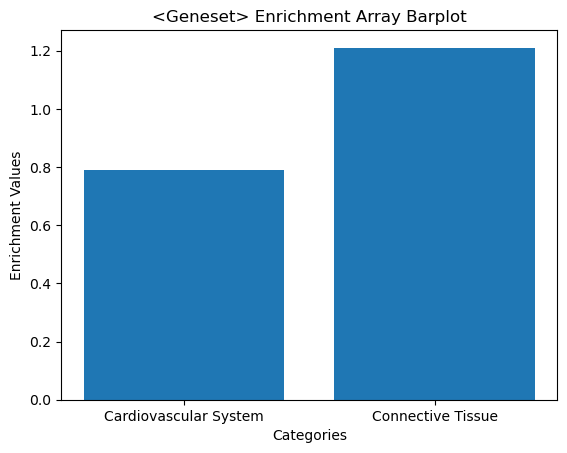

In [15]:
def plot_individual_geneset_matrix(enrichment_values, category_dict):
    # Extract the category names from the dictionary keys
    categories = list(category_dict.keys())

    # Plotting the barplots
    plt.bar(categories, enrichment_values)

    # Add labels and title
    plt.xlabel('Categories')
    plt.ylabel('Enrichment Values')
    plt.title('<Geneset> Enrichment Array Barplot')

    # Display the plot
    plt.show()
    
plot_individual_geneset_matrix(enrichment_values, category_dict)

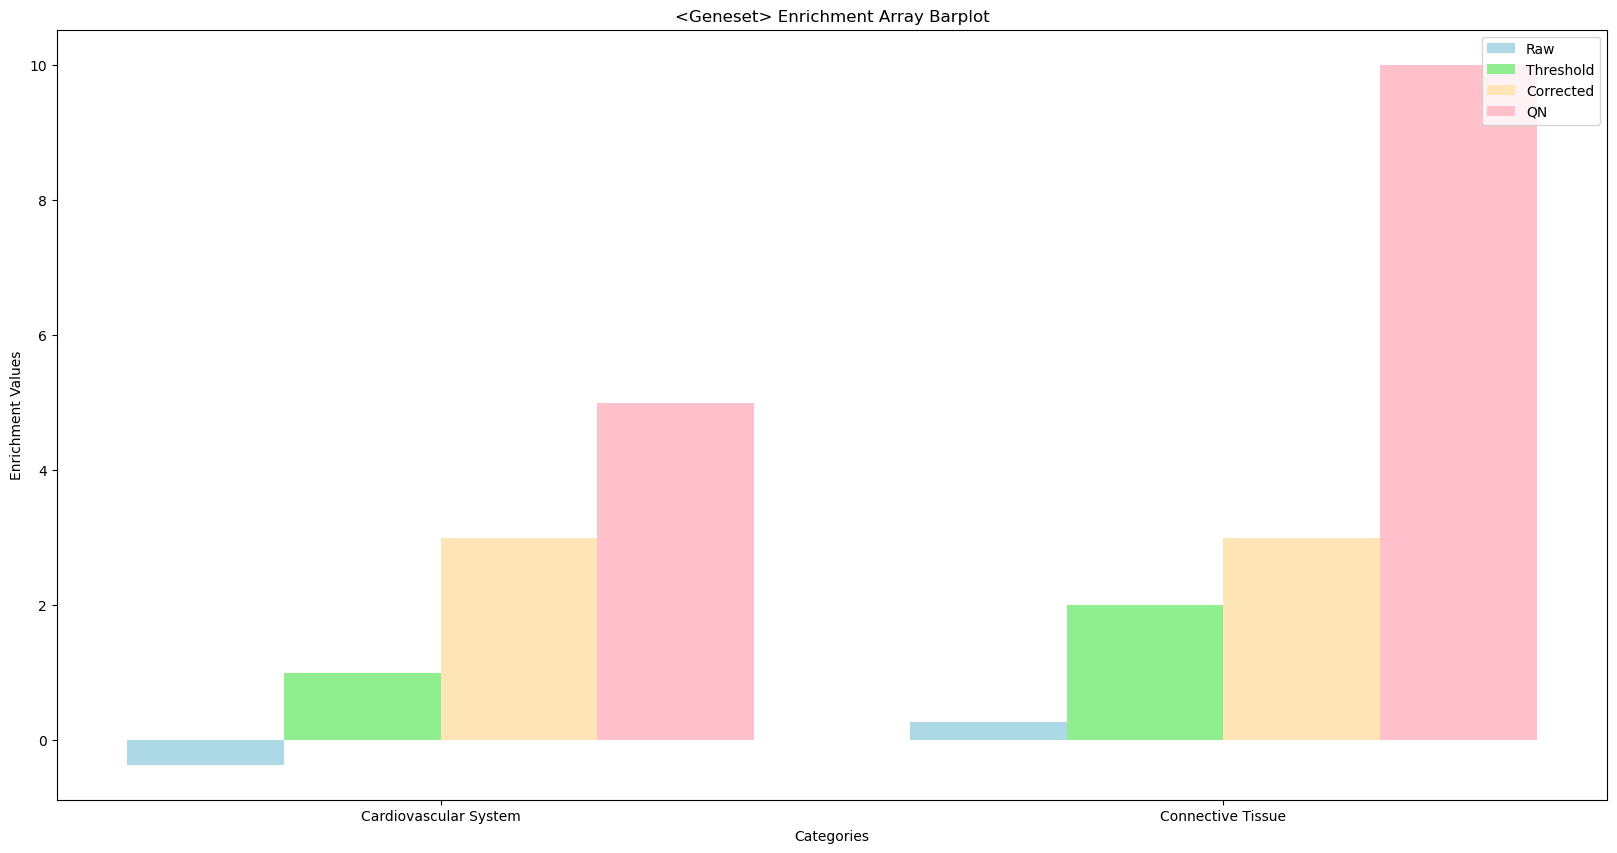

In [30]:
# Plot All Systems 

def plot_geneset_across_matrixes(enrichment_values, category_dict, processed_matrix_names):
    # Extract the category names from the dictionary keys
    categories = list(category_dict.keys())

    # Set the width of each bar
    bar_width = 0.2

    # Calculate the x-axis positions for each bar
    x_positions = np.arange(len(categories))
    
    # Increase figure width
    plt.figure(figsize=(20, 10))

    # Define the colors for each matrix
    colors = ["lightblue", "lightgreen", "moccasin", "pink"]

    # Plotting the barplots for each row in enrichment_values
    for i in range(enrichment_values.shape[0]):
        center_offset = (enrichment_values.shape[0] - 1) * bar_width / 2  # Offset to center the bars
        plt.bar(x_positions + (i * bar_width) - center_offset, enrichment_values[i], width=bar_width, label=processed_matrix_names[i], color=colors[i])

    # Add labels and title
    plt.xlabel('Categories')
    plt.ylabel('Enrichment Values')
    plt.title('<Geneset> Enrichment Array Barplot')
    plt.xticks(x_positions, categories)
    plt.legend(loc='upper right')

    # Display the plot
    plt.show()

# Example usage
enrichment_values = np.array([[-0.36014562, 0.26769307], [1, 2], [3, 3], [5,10]])
category_dict = {"Cardiovascular System": ["heart", "atrium"], "Connective Tissue": ["adipose"]}
processed_matrix_names = ["Raw", "Threshold", "Corrected", "QN"]

plot_geneset_across_matrixes(enrichment_values, category_dict, processed_matrix_names)


In [25]:
enrichment_values

array([[-0.36014562,  0.26769307],
       [ 1.        ,  2.        ],
       [ 3.        ,  3.        ],
       [ 5.        , 10.        ]])

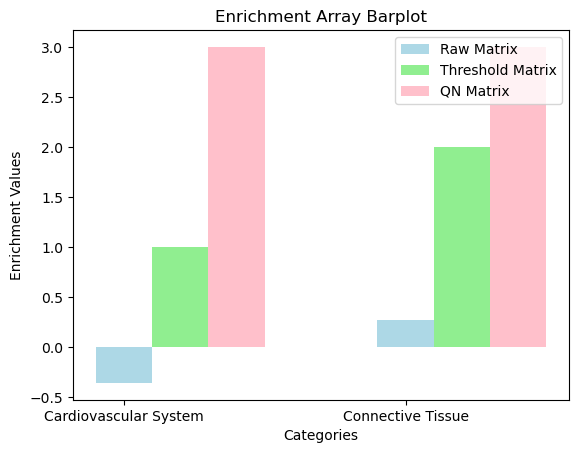

In [12]:
# Plot Raw, Threshold, QN
def plot_geneset_across_matrixes(enrichment_values, category_dict, processed_matrix_names):
    # Extract the category names from the dictionary keys
    categories = list(category_dict.keys())

    # Set the width of each bar
    bar_width = 0.2

    # Calculate the x-axis positions for each bar
    x_positions = np.arange(len(categories))

    # Define the colors for each matrix
    colors = ["lightblue", "lightgreen", "pink"]

    # Plotting the barplots for each row in enrichment_values
    for i in range(enrichment_values.shape[0]):
        plt.bar(x_positions + (i * bar_width), enrichment_values[i], width=bar_width, label=processed_matrix_names[i], color=colors[i])

    # Add labels and title
    plt.xlabel('Categories')
    plt.ylabel('Enrichment Values')
    plt.title('Enrichment Array Barplot')
    plt.xticks(x_positions, categories)
    plt.legend()

    # Display the plot
    plt.show()

# Example usage
enrichment_values = np.array([[-0.36014562, 0.26769307], [1, 2], [3, 3]])
category_dict = {"Cardiovascular System": ["heart", "atrium"], "Connective Tissue": ["adipose"]}
processed_matrix_names = ["Raw Matrix", "Threshold Matrix", "QN Matrix"]

plot_geneset_across_matrixes(enrichment_values, category_dict, processed_matrix_names)